<style>
.custom-spacing {
    line-height: 0.5;
}
</style>

### <center>*Tugas Mata Kuliah*</center>
### <center>*Kecerdasan Artifisial Untuk Geofisika*</center>

<div style="text-align:center;">
  <img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" alt="Deskripsi Gambar" style="width:280px;">
</div>

### <center>*OLEH :*</center>


#### <center>ANDI NURUL MAZAYA (H061241087)<center>



### <center>*PROGRAM STUDI GEOFISIKA*</center>
### <center>*FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM*</center>
#### <center>*UNIVERSITAS HASANUDDIN*</center>
#### <center>*MAKASSAR*</center>
#### <center>*2025*</center>

<hr>

# Analisis Deret Waktu Data Gempa Maret 2023
### Implementasi Recipe R-VIS-001 — *Membuat Time-Series Figure yang Informatif*

Notebook ini mengimplementasikan recipe dari *AI Cookbook untuk Earth Sciences* pada katalog gempa bulan Maret 2023. Notebook disusun dengan sel Markdown untuk penjelasan dan sel Python untuk menjalankan analisis.

**Tujuan analisis**
1. Membaca katalog gempa dari file CSV.
2. Memeriksa struktur dan kualitas data.
3. Mengubah kolom tanggal dan waktu menjadi format yang dapat diolah.
4. Menghitung statistik magnitudo dan jumlah kejadian harian.
5. Membuat grafik deret waktu magnitudo dan jumlah kejadian harian.
6. Menyimpan grafik dalam format PNG dan PDF serta ringkasan harian dalam CSV.

**Catatan penting:** notebook ini tidak mengubah atau menghapus nilai asli pada data sumber. Hasil pemeriksaan kualitas data hanya ditampilkan sebagai informasi untuk ditinjau.

## 1. Persiapan lingkungan

Notebook menggunakan pustaka `pandas` untuk pengolahan data, `matplotlib` untuk visualisasi, dan `pathlib` untuk pengelolaan lokasi file.

Jika pustaka belum tersedia, jalankan perintah instalasi di sel berikut. Di Jupyter Notebook atau VS Code, sel instalasi dapat dijalankan dengan menghapus tanda komentar `#`.

In [6]:
# Jika pustaka belum terpasang, hapus tanda # pada baris berikut lalu jalankan:
# %pip install pandas matplotlib

## 2. Impor pustaka

Bagian ini memanggil pustaka yang diperlukan untuk membaca CSV, memproses tanggal, menghitung statistik, dan membuat grafik.

In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 3. Membaca data CSV

Letakkan file `Gabungan Mar.csv` di folder yang sama dengan notebook ini. Jika nama atau lokasi file berbeda, ubah nilai `FILE_CSV` pada sel di bawah.

File dibaca dengan `encoding="utf-8"` terlebih dahulu. Jika terjadi masalah encoding, coba `encoding="latin1"`. Pemisah kolom yang digunakan adalah koma.

In [8]:
# Ubah path ini jika file CSV berada di folder lain.
FILE_CSV = Path("Gabungan Mar.csv")

if not FILE_CSV.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {FILE_CSV.resolve()}\n"
        "Letakkan 'Gabungan Mar.csv' di folder yang sama dengan notebook "
        "atau ubah variabel FILE_CSV ke lokasi file yang benar."
    )

try:
    df = pd.read_csv(FILE_CSV, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(FILE_CSV, encoding="latin1")

print(f"Jumlah baris: {len(df)}")
print(f"Jumlah kolom: {len(df.columns)}")
display(df.head())

Jumlah baris: 368
Jumlah kolom: 9


,No,Tanggal,Waktu (UTC),Mag,Lat,Long,Depth,Keterangan,Dirasakan
0,1,1-Mar-23,0:03:37,2.3,-1.60,120.17,2,39 km Tenggara SIGI-SULTENG,NaN
1,2,1-Mar-23,2:03:21 AM,3.5,-1.61,120.23,2,47 km Tenggara SIGI-SULTENG,NaN
2,3,1-Mar-23,3:05:03,2.5,-1.62,120.20,2,43 km Tenggara SIGI-SULTENG,NaN
3,4,1-Mar-23,4:12:56,2.3,-0.45,121.81,3,76 km TimurLaut TOJOUNA-UNA-SULTENG,NaN
4,5,1-Mar-23,12:08:06,2.4,-1.63,120.21,5,45 km Tenggara SIGI-SULTENG,NaN


## 4. Memeriksa struktur data

Tahap ini menampilkan nama kolom, tipe data, ukuran tabel, dan contoh isi data. Pemeriksaan dilakukan sebelum pengolahan lebih lanjut agar nama kolom yang digunakan di kode sesuai dengan file sumber.

In [9]:
print("Nama kolom:")
print(df.columns.tolist())

print("\nInformasi tipe data:")
df.info()

print("\nLima baris pertama:")
display(df.head())

Nama kolom:
['No', 'Tanggal', 'Waktu (UTC)', 'Mag', 'Lat', 'Long', 'Depth', 'Keterangan', 'Dirasakan']

Informasi tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 368 entries, 0 to 367
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   No           368 non-null    int64  
 1   Tanggal      368 non-null    str    
 2   Waktu (UTC)  368 non-null    str    
 3   Mag          368 non-null    float64
 4   Lat          368 non-null    float64
 5   Long         368 non-null    float64
 6   Depth        368 non-null    int64  
 7   Keterangan   366 non-null    str    
 8   Dirasakan    12 non-null     str    
dtypes: float64(3), int64(2), str(4)
memory usage: 26.0 KB

Lima baris pertama:


,No,Tanggal,Waktu (UTC),Mag,Lat,Long,Depth,Keterangan,Dirasakan
0,1,1-Mar-23,0:03:37,2.3,-1.60,120.17,2,39 km Tenggara SIGI-SULTENG,NaN
1,2,1-Mar-23,2:03:21 AM,3.5,-1.61,120.23,2,47 km Tenggara SIGI-SULTENG,NaN
2,3,1-Mar-23,3:05:03,2.5,-1.62,120.20,2,43 km Tenggara SIGI-SULTENG,NaN
3,4,1-Mar-23,4:12:56,2.3,-0.45,121.81,3,76 km TimurLaut TOJOUNA-UNA-SULTENG,NaN
4,5,1-Mar-23,12:08:06,2.4,-1.63,120.21,5,45 km Tenggara SIGI-SULTENG,NaN


## 5. Pemeriksaan kualitas data

Bagian ini memeriksa nilai kosong dan baris duplikat. Pemeriksaan ini tidak otomatis menghapus atau memperbaiki data. Jika ada nilai kosong atau duplikat, hasilnya perlu ditinjau berdasarkan sumber katalog gempa.

In [10]:
# Jumlah nilai kosong untuk setiap kolom
missing_summary = df.isna().sum().rename("Jumlah nilai kosong").to_frame()
missing_summary["Persentase (%)"] = (df.isna().mean() * 100).round(2)
display(missing_summary)

# Pemeriksaan baris duplikat secara keseluruhan
duplicate_count = int(df.duplicated().sum())
print(f"Jumlah baris duplikat persis: {duplicate_count}")

# Pemeriksaan jumlah nilai unik pada kolom jika tersedia
print("\nJumlah nilai unik per kolom:")
display(df.nunique(dropna=True).rename("Jumlah nilai unik").to_frame())

,Jumlah nilai kosong,Persentase (%)
No,0,0.00
Tanggal,0,0.00
Waktu (UTC),0,0.00
Mag,0,0.00
Lat,0,0.00
Long,0,0.00
Depth,0,0.00
Keterangan,2,0.54
Dirasakan,356,96.74


Jumlah baris duplikat persis: 0

Jumlah nilai unik per kolom:


,Jumlah nilai unik
No,368
Tanggal,31
Waktu (UTC),366
Mag,38
Lat,169
Long,170
Depth,51
Keterangan,225
Dirasakan,12


## 6. Menyiapkan kolom tanggal dan magnitudo

Berdasarkan struktur katalog, kolom yang digunakan adalah `Tanggal`, `Waktu (UTC)`, `Mag`, `Lat`, `Long`, dan `Depth`.

Kolom `Tanggal` pada file sumber berformat seperti `01-Mar-23`. Kode berikut mengonversinya menjadi tipe tanggal. Kolom numerik dikonversi secara hati-hati; nilai yang tidak dapat dikonversi akan menjadi nilai kosong pada kolom hasil olahan, sedangkan tabel asli `df` tetap dipertahankan.

In [11]:
# Pastikan nama kolom yang dibutuhkan tersedia.
required_columns = ["Tanggal", "Mag", "Lat", "Long", "Depth"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise KeyError(
        "Kolom berikut tidak ditemukan pada CSV: "
        + ", ".join(missing_columns)
        + "\nPeriksa nama kolom pada bagian struktur data."
    )

# Salinan untuk analisis; data sumber df tidak diubah.
data = df.copy()

# Konversi tanggal. Format sumber diperkirakan seperti 01-Mar-23.
data["Tanggal_analisis"] = pd.to_datetime(
    data["Tanggal"], format="%d-%b-%y", errors="coerce"
)

# Konversi variabel numerik yang digunakan.
for col in ["Mag", "Lat", "Long", "Depth"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Buang hanya dari tabel analisis baris yang tidak memiliki tanggal valid.
# Tabel sumber df tetap tidak berubah.
data_valid = data.loc[data["Tanggal_analisis"].notna()].copy()

print(f"Jumlah baris pada CSV sumber: {len(df)}")
print(f"Baris dengan tanggal valid: {len(data_valid)}")
print(f"Baris dengan tanggal tidak valid: {len(data) - len(data_valid)}")
display(data_valid.head())

Jumlah baris pada CSV sumber: 368
Baris dengan tanggal valid: 368
Baris dengan tanggal tidak valid: 0


,No,Tanggal,Waktu (UTC),Mag,Lat,Long,Depth,Keterangan,Dirasakan,Tanggal_analisis
0,1,1-Mar-23,0:03:37,2.3,-1.60,120.17,2,39 km Tenggara SIGI-SULTENG,NaN,2023-03-01
1,2,1-Mar-23,2:03:21 AM,3.5,-1.61,120.23,2,47 km Tenggara SIGI-SULTENG,NaN,2023-03-01
2,3,1-Mar-23,3:05:03,2.5,-1.62,120.20,2,43 km Tenggara SIGI-SULTENG,NaN,2023-03-01
3,4,1-Mar-23,4:12:56,2.3,-0.45,121.81,3,76 km TimurLaut TOJOUNA-UNA-SULTENG,NaN,2023-03-01
4,5,1-Mar-23,12:08:06,2.4,-1.63,120.21,5,45 km Tenggara SIGI-SULTENG,NaN,2023-03-01


## 7. Ringkasan statistik katalog

Statistik berikut merangkum magnitudo, lintang, bujur, dan kedalaman. Nilai kedalaman ditampilkan sesuai angka pada CSV; satuannya tidak diasumsikan karena satuan tidak tercantum secara eksplisit pada nama kolom sumber.

In [12]:
numeric_columns = ["Mag", "Lat", "Long", "Depth"]
display(data_valid[numeric_columns].describe().T)

print(f"Rentang tanggal: {data_valid['Tanggal_analisis'].min():%d %B %Y} "
      f"sampai {data_valid['Tanggal_analisis'].max():%d %B %Y}")
print(f"Jumlah kejadian dengan tanggal valid: {len(data_valid)}")

,count,mean,std,min,25%,50%,75%,max
Mag,368.0,2.376630,0.665087,0.10,1.9000,2.300,2.7000,5.50
Lat,368.0,-1.972671,1.228305,-7.43,-2.5125,-1.630,-1.5800,-0.03
Long,368.0,123.443696,52.102065,118.15,120.1800,120.225,121.1925,1120.01
Depth,368.0,14.369565,39.402338,1.00,3.0000,5.000,8.0000,476.00


Rentang tanggal: 01 March 2023 sampai 31 March 2023
Jumlah kejadian dengan tanggal valid: 368


## 8. Ringkasan kejadian gempa per hari

Data dikelompokkan berdasarkan tanggal untuk menghitung:
- jumlah kejadian gempa per hari;
- magnitudo maksimum per hari;
- magnitudo rata-rata per hari.

Hari tanpa catatan kejadian tidak ditambahkan sebagai nol secara otomatis. Dengan demikian, tabel ini merangkum tanggal yang memang tercatat di dalam katalog.

In [13]:
daily_summary = (
    data_valid.groupby(data_valid["Tanggal_analisis"].dt.normalize())
    .agg(
        jumlah_kejadian=("Mag", "size"),
        magnitudo_maksimum=("Mag", "max"),
        magnitudo_rata_rata=("Mag", "mean"),
    )
    .rename_axis("Tanggal")
    .reset_index()
)

daily_summary["magnitudo_rata_rata"] = daily_summary["magnitudo_rata_rata"].round(3)

display(daily_summary.head(10))
print("\nTanggal dengan jumlah kejadian tertinggi:")
display(daily_summary.loc[daily_summary["jumlah_kejadian"].idxmax()].to_frame("Nilai"))

,Tanggal,jumlah_kejadian,magnitudo_maksimum,magnitudo_rata_rata
0,2023-03-01,23,3.5,2.130
1,2023-03-02,5,3.3,2.640
2,2023-03-03,18,4.9,2.556
3,2023-03-04,25,4.8,2.584
4,2023-03-05,15,3.6,2.193
5,2023-03-06,16,4.5,2.206
6,2023-03-07,8,4.6,2.575
7,2023-03-08,11,3.4,2.373
8,2023-03-09,14,2.9,2.300
9,2023-03-10,9,2.7,2.267



Tanggal dengan jumlah kejadian tertinggi:


,Nilai
Tanggal,2023-03-11 00:00:00
jumlah_kejadian,39
magnitudo_maksimum,3.7
magnitudo_rata_rata,2.215


## 9. Membuat visualisasi deret waktu

Sesuai recipe **R-VIS-001**, visualisasi dibuat dengan dua panel:
1. **Magnitudo terhadap waktu:** setiap titik mewakili satu catatan gempa. Garis menunjukkan magnitudo maksimum harian, bukan lintasan setiap kejadian.
2. **Jumlah kejadian harian:** batang menunjukkan jumlah catatan gempa pada tanggal tersebut.

Tanggal pada sumbu horizontal mengikuti kolom `Tanggal` pada sumber. Kolom `Waktu (UTC)` tidak digunakan untuk menggeser tanggal atau menentukan urutan intrahari pada grafik ini. Grafik ini adalah ringkasan harian, bukan analisis waktu kejadian hingga tingkat jam.

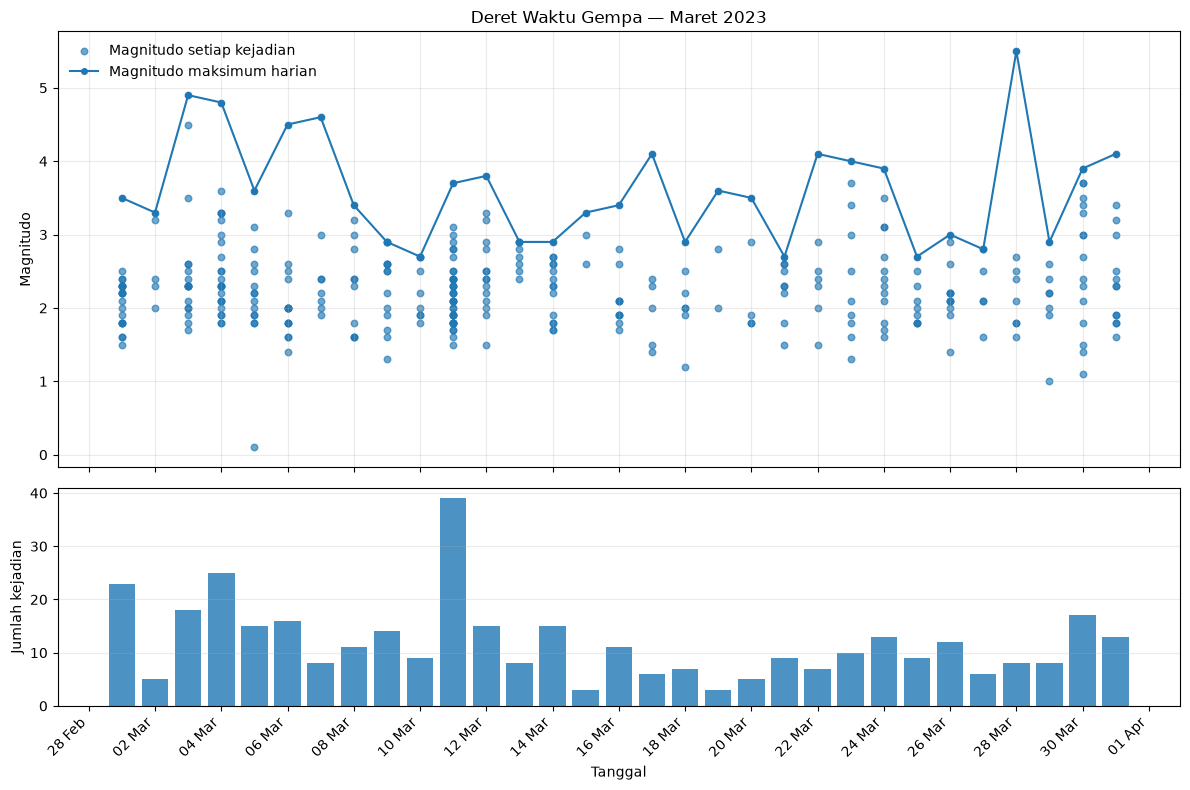

In [14]:
# Siapkan tanggal harian untuk setiap kejadian.
data_valid["Tanggal_harian"] = data_valid["Tanggal_analisis"].dt.normalize()

# Ukuran gambar dibuat agar tetap mudah dibaca pada laporan.
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

# Panel 1: magnitudo setiap kejadian dan magnitudo maksimum harian
axes[0].scatter(
    data_valid["Tanggal_analisis"],
    data_valid["Mag"],
    s=22,
    alpha=0.65,
    label="Magnitudo setiap kejadian"
)
axes[0].plot(
    daily_summary["Tanggal"],
    daily_summary["magnitudo_maksimum"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Magnitudo maksimum harian"
)
axes[0].set_ylabel("Magnitudo")
axes[0].set_title("Deret Waktu Gempa — Maret 2023")
axes[0].grid(True, alpha=0.25)
axes[0].legend(frameon=False)

# Panel 2: jumlah kejadian per hari
axes[1].bar(
    daily_summary["Tanggal"],
    daily_summary["jumlah_kejadian"],
    width=0.8,
    alpha=0.8
)
axes[1].set_ylabel("Jumlah kejadian")
axes[1].set_xlabel("Tanggal")
axes[1].grid(axis="y", alpha=0.25)

# Format tanggal agar label tidak bertumpuk.
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")

fig.tight_layout()
plt.show()

## 10. Menyimpan grafik dan tabel ringkasan

Grafik disimpan sebagai PNG dengan resolusi 300 dpi dan sebagai PDF untuk digunakan dalam laporan. Ringkasan kejadian harian disimpan sebagai CSV.

Berkas hasil akan tersimpan di folder kerja aktif Jupyter/VS Code.

In [15]:
OUTPUT_DIR = Path("hasil_analisis_gempa")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

png_path = OUTPUT_DIR / "visualisasi_gempa_maret_2023.png"
pdf_path = OUTPUT_DIR / "visualisasi_gempa_maret_2023.pdf"
csv_path = OUTPUT_DIR / "ringkasan_harian_gempa_maret_2023.csv"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
daily_summary.to_csv(csv_path, index=False, encoding="utf-8-sig")

print("Berkas berhasil disimpan:")
print(f"- Grafik PNG : {png_path.resolve()}")
print(f"- Grafik PDF : {pdf_path.resolve()}")
print(f"- Ringkasan  : {csv_path.resolve()}")

Berkas berhasil disimpan:
- Grafik PNG : C:\Users\axioo pongo\Downloads\hasil_analisis_gempa\visualisasi_gempa_maret_2023.png
- Grafik PDF : C:\Users\axioo pongo\Downloads\hasil_analisis_gempa\visualisasi_gempa_maret_2023.pdf
- Ringkasan  : C:\Users\axioo pongo\Downloads\hasil_analisis_gempa\ringkasan_harian_gempa_maret_2023.csv


## 11. Pemeriksaan nilai kedalaman

Dalam pemeriksaan awal katalog ini, nilai kedalaman maksimum jauh lebih besar dibandingkan median. Hal tersebut **tidak otomatis berarti salah**, tetapi sebaiknya diperiksa kembali ke sumber data atau metadata katalog. Kode berikut menampilkan beberapa catatan dengan kedalaman terbesar untuk memudahkan pengecekan.

Satuan kedalaman tidak disimpulkan dari angka saja karena nama kolom sumber hanya tertulis `Depth`.

In [16]:
depth_check_columns = [
    col for col in ["Tanggal", "Waktu (UTC)", "Mag", "Lat", "Long", "Depth", "Keterangan"]
    if col in data_valid.columns
]

display(
    data_valid.nlargest(10, "Depth")[depth_check_columns]
    .sort_values("Depth", ascending=False)
)

print(f"Median Depth: {data_valid['Depth'].median()}")
print(f"Nilai Depth maksimum: {data_valid['Depth'].max()}")
print("Catatan: periksa nilai ekstrem menggunakan sumber katalog; tidak ada nilai yang diubah oleh notebook ini.")

,Tanggal,Waktu (UTC),Mag,Lat,Long,Depth,Keterangan
286,24-Mar-23,10:41:22,3.9,-7.37,119.84,476,125 km BaratLaut LABUANBAJO-NTT
52,4-Mar-23,3:11:20,3.3,-7.43,119.91,393,118 km Timurlaut LABUANBAJO-NTT
285,24-Mar-23,12:06:57,2.2,-0.03,122.79,202,73 km BaratDaya BONEBOLANGO-GORONTALO
277,23-Mar-23,15:31:56,3.7,-0.07,123.28,167,69 km Tenggara BONEBOLANGO-GORONTALO
261,21-Mar-23,13:02:29,2.7,-0.19,123.11,131,80 km BaratDaya BONEBOLANGO-GORONTALO
86,6-Mar-23,2:42:23,4.5,-0.12,123.12,123,75 km BaratDaya BONEBOLANGO-GORONTALO
270,22-Mar-23,13:05:26,2.9,-0.10,122.88,118,76 km BaratDaya BONEBOLANGO-GORONTALO
144,11-Mar-23,0:12:43,3.7,-0.29,123.00,115,88 km BaratDaya BONEBOLANGO-GORONTALO
219,14-Mar-23,19:13:46,2.9,-0.06,123.11,114,71 km BaratDaya BONEBOLANGO-GORONTALO
349,30-Mar-23,19:24:56,3.3,-0.31,123.06,106,94 km BaratDaya BONEBOLANGO-GORONTALO


Median Depth: 5.0
Nilai Depth maksimum: 476
Catatan: periksa nilai ekstrem menggunakan sumber katalog; tidak ada nilai yang diubah oleh notebook ini.


## 12. Interpretasi awal hasil

Gunakan hasil statistik dan grafik untuk menjawab pertanyaan berikut saat menulis laporan:

- Bagaimana sebaran magnitudo gempa selama Maret 2023?
- Pada tanggal berapa jumlah catatan gempa paling banyak?
- Apakah tanggal dengan jumlah kejadian tertinggi juga memiliki magnitudo maksimum tertinggi?
- Apakah terdapat nilai kedalaman yang perlu diverifikasi terhadap sumber data?
- Apakah kolom `Dirasakan` dan `Keterangan` cukup lengkap untuk analisis lanjutan?

Interpretasi harus mengikuti hasil yang benar-benar ditampilkan notebook. Grafik deret waktu saja belum cukup untuk menyimpulkan mekanisme tektonik, penyebab gempa, atau tingkat bahaya suatu wilayah.

## 13. Kesimpulan

Recipe **R-VIS-001 — Membuat Time-Series Figure yang Informatif** diterapkan untuk menyajikan katalog gempa dalam bentuk grafik magnitudo terhadap tanggal dan jumlah kejadian harian. Notebook juga menyertakan pemeriksaan struktur data, nilai kosong, statistik ringkas, dan pemeriksaan nilai kedalaman ekstrem.

**Batasan analisis**
- Tanggal diambil dari kolom `Tanggal`; waktu dalam jam-menit tidak dianalisis pada grafik ini.
- Satuan kedalaman perlu dipastikan dari metadata atau sumber katalog.
- Nilai kosong pada kolom deskriptif seperti `Dirasakan` tidak diisi secara otomatis.
- Visualisasi bersifat deskriptif dan tidak dengan sendirinya menjelaskan penyebab geologi dari pola gempa.

### Sumber
Recipe R-VIS-001, *Membuat Time-Series Figure yang Informatif*, dari dokumen *AI Cookbook untuk Earth Sciences* yang disertakan bersama tugas ini.